Arica Bhuiyan  
Final Python Notebook 2  

This notebook contains classification models for loan approval prediction.  


This section imports the required libraries.

Code reused from:
- Seminar 2: Data Visualisation  
- Seminar 3: Data Preprocessing  
- Seminar 4: Model Training  

This section loads the prepared dataset from Notebook 1.

Code reused from Seminar 1.

In [ ]:
# Import pandas library
import pandas as pd

import matplotlib.pyplot as plt

# Import Logistic Regression model
from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import confusion_matrix

# Import classification report function
from sklearn.metrics import classification_report

from sklearn.metrics import ConfusionMatrixDisplay

# Import ROC curve display
from sklearn.metrics import RocCurveDisplay

from sklearn.metrics import accuracy_score

Ive used this code in seminar 2 and 3, loading the prepared classification dataset from Notebook 1.

In [ ]:
# Load the prepared classification dataset
df = pd.read_csv("loan_data_prepared.csv")

# View the first rows of the prepared dataset
df.head()

,age,sex,education_qualifications,income,home_ownership,employment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status
0,21.0,2,5,12000.0,2,0.0,1,15000,6.99,0.12,0,4,1
1,21.0,2,5,13200.0,2,2.0,1,25000,16.77,0.19,2,3,1
2,23.0,2,5,9600.0,3,5.0,3,30000,12.42,0.31,0,3,1
3,40.0,2,5,182004.0,3,3.0,1,35000,8.00,0.19,0,11,1
4,40.0,2,5,90000.0,0,3.0,2,35000,12.42,0.39,0,14,1


featurinf matrix and target variables from seminar 3

In [ ]:
# Define the feature matrix
X = df.drop('loan_approval_status', axis=1)

# Define the target variable
y = df['loan_approval_status']

showing names and data set shaoes from tutorial 3

In [ ]:

print(X.columns)


print(df.shape)

Index(['age', 'sex', 'education_qualifications', 'income', 'home_ownership',
       'employment_length', 'loan_intent', 'loan_amount', 'loan_interest_rate',
       'loan_income_ratio', 'payment_default_on_file',
       'credit_history_length'],
      dtype='object')
(58645, 13)


Im doing the split function and training and testing nets

In [ ]:
# Import train test split function
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


 checking the split sizes and target class balance from tutorial 3

In [ ]:
# Print the shapes of the training and testing sets
print(X_train.shape, X_test.shape)

# Print the training target distribution
print(y_train.value_counts())

# Print the testing target distribution
print(y_test.value_counts())

(46916, 12) (11729, 12)
loan_approval_status
1    40236
0     6680
Name: count, dtype: int64
loan_approval_status
1    10059
0     1670
Name: count, dtype: int64


building the Logistic Regression model from tutorial 3

In [ ]:
# Create the Logistic Regression model
lr = LogisticRegression(max_iter=5000)

# Train the Logistic Regression model
lr.fit(X_train, y_train)

# Predict the test labels using Logistic Regression
y_pred_lr = lr.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Code reused from Seminar 4 and Code Reuse Session 2 - evaluating the Logistic Regression model.

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.76      0.36      0.49      1670
           1       0.90      0.98      0.94     10059

    accuracy                           0.89     11729
   macro avg       0.83      0.67      0.72     11729
weighted avg       0.88      0.89      0.88     11729



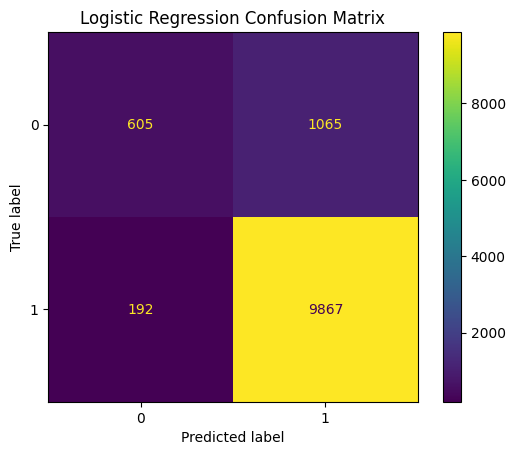

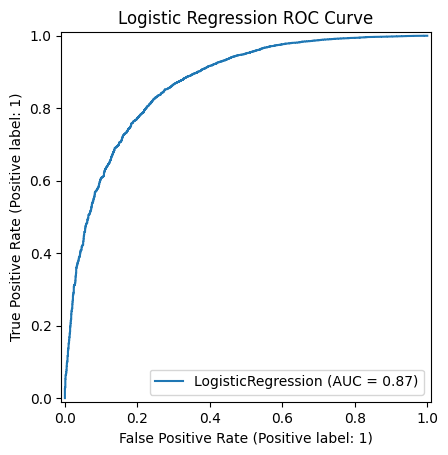

In [ ]:
# Print the Logistic Regression classification report
print("Logistic Regression Classification Report")
print(classification_report(y_test, y_pred_lr))

# Create the Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Display the Logistic Regression confusion matrix
ConfusionMatrixDisplay(cm_lr).plot()

# Add the confusion matrix title
plt.title("Logistic Regression Confusion Matrix")

# Show the confusion matrix
plt.show()

# Display the Logistic Regression ROC curve
RocCurveDisplay.from_estimator(lr, X_test, y_test)

# Add the ROC curve title
plt.title("Logistic Regression ROC Curve")

# Show the ROC curve
plt.show()

building the K Nearest Neighbour model from code reuse 2 and 3

In [ ]:
# Create the KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the KNN model
knn.fit(X_train, y_train)

# Predict the test labels using KNN
y_pred_knn = knn.predict(X_test)

evaluating the K Nearest Neighbour model from tutorial 4 and codereuse 2

KNN Classification Report
              precision    recall  f1-score   support

           0       0.67      0.51      0.58      1670
           1       0.92      0.96      0.94     10059

    accuracy                           0.89     11729
   macro avg       0.80      0.73      0.76     11729
weighted avg       0.89      0.89      0.89     11729



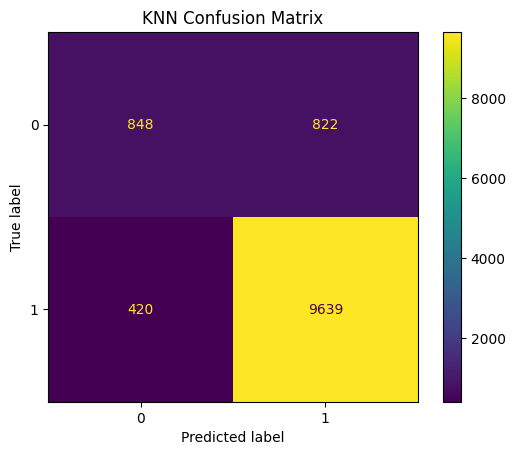

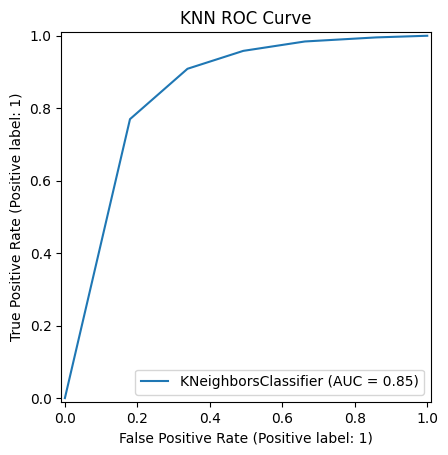

In [ ]:
# Print the KNN classification report
print("KNN Classification Report")
print(classification_report(y_test, y_pred_knn))

# Create the KNN confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Display the KNN confusion matrix
ConfusionMatrixDisplay(cm_knn).plot()

# Add the confusion matrix title
plt.title("KNN Confusion Matrix")

# Show the confusion matrix
plt.show()

# Display the KNN ROC curve
RocCurveDisplay.from_estimator(knn, X_test, y_test)

# Add the ROC curve title
plt.title("KNN ROC Curve")

# Show the ROC curve
plt.show()

building the Naive Bayes model.

In [ ]:
# Create the Naive Bayes model
nb = GaussianNB()

# Train the Naive Bayes model
nb.fit(X_train, y_train)

# Predict the test labels using Naive Bayes
y_pred_nb = nb.predict(X_test)

Cevaluating the Naive Bayes model from seminar 4

Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.70      0.27      0.39      1670
           1       0.89      0.98      0.93     10059

    accuracy                           0.88     11729
   macro avg       0.80      0.63      0.66     11729
weighted avg       0.86      0.88      0.86     11729



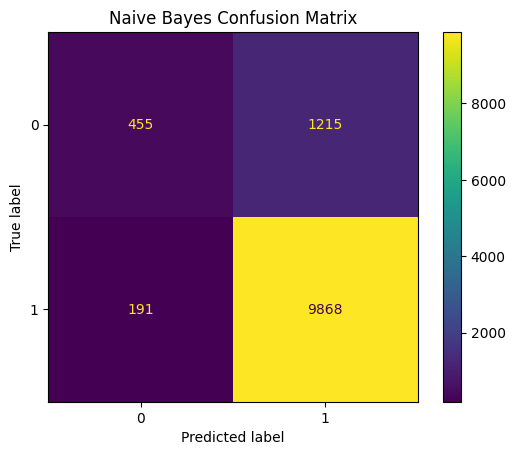

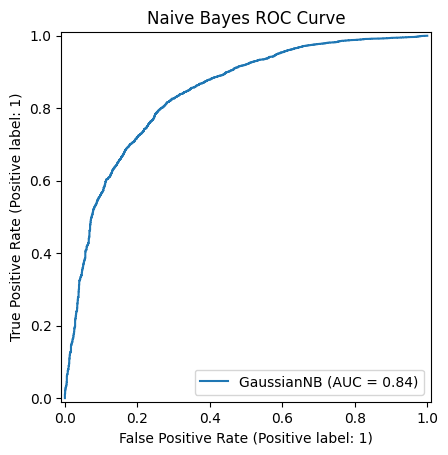

In [ ]:
# Print the Naive Bayes classification report
print("Naive Bayes Classification Report")
print(classification_report(y_test, y_pred_nb))

# Create the Naive Bayes confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

# Display the Naive Bayes confusion matrix
ConfusionMatrixDisplay(cm_nb).plot()

# Add the confusion matrix title
plt.title("Naive Bayes Confusion Matrix")

# Show the confusion matrix
plt.show()

# Display the Naive Bayes ROC curve
RocCurveDisplay.from_estimator(nb, X_test, y_test)

# Add the ROC curve title
plt.title("Naive Bayes ROC Curve")

# Show the ROC curve
plt.show()

comparing the three model accuracy scores from code reuse session

In [ ]:
# Print the Logistic Regression accuracy
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))

# Print the KNN accuracy
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

# Print the Naive Bayes accuracy
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

Logistic Regression Accuracy: 0.8928297382556057
KNN Accuracy: 0.8941086196606701
Naive Bayes Accuracy: 0.8801261829652997


Code reused from Code Reuse Session 2 - applying GridSearchCV for KNN hyperparameter tuning.

In [ ]:
# Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {'n_neighbors': [3, 5, 7]}

# Create the GridSearchCV object
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=3)

# Train the GridSearchCV model
grid.fit(X_train, y_train)

# Print the best parameters
print(grid.best_params_)

{'n_neighbors': 7}


Code reused from Code Reuse Session 2 - evaluating the tuned KNN model.

Tuned KNN Classification Report
              precision    recall  f1-score   support

           0       0.69      0.49      0.57      1670
           1       0.92      0.96      0.94     10059

    accuracy                           0.90     11729
   macro avg       0.80      0.73      0.76     11729
weighted avg       0.89      0.90      0.89     11729



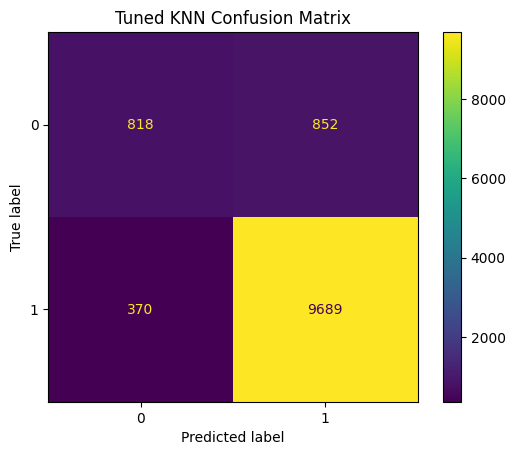

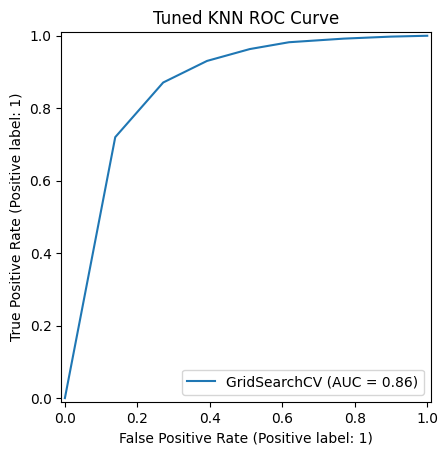

In [ ]:
# Predict the test labels using the tuned KNN model
y_pred_tuned = grid.predict(X_test)

# Print the tuned KNN classification report
print("Tuned KNN Classification Report")
print(classification_report(y_test, y_pred_tuned))

# Create the tuned KNN confusion matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

# Display the tuned KNN confusion matrix
ConfusionMatrixDisplay(cm_tuned).plot()

# Add the confusion matrix title
plt.title("Tuned KNN Confusion Matrix")

# Show the confusion matrix
plt.show()

# Display the tuned KNN ROC curve
RocCurveDisplay.from_estimator(grid, X_test, y_test)

# Add the ROC curve title
plt.title("Tuned KNN ROC Curve")

# Show the ROC curve
plt.show()

Peer Review  

Reviewer/group: Muller Zerufael/ Timeout   

Date: 09/03/26

Checks:
- models executed successfully  
- predictions generated  
- evaluation metrics calculated  

Result:
All models performed as expected